# Two-layer QG testbed: 4DVarNet vs 4DVar, and the Lyapunov view of the gain

Whole pipeline in one notebook (same code as the hydra xps `qg2l_*`, see `contrib/qg2l/README.md`):

1. truth run + nadir / SWOT observations, figures and animation
2. 4DVarNet training / test (state = psi_1, psi_2; SSH observations only)
3. cycled 4DVar, strong and weak constraint (imperfect low-resolution model, autograd adjoint)
4. comparison plots and scores
5. projection of the reconstruction errors on the BLV / CLV of the DA model

`SIZE = "small"` (default) runs everything on a 32x32, 500 km box in minutes on a GPU (longer on CPU);
`SIZE = "full"` is the 64x64, 1000 km set-up of the hydra configs (GPU, hours).

In [1]:
import os, sys, json
from pathlib import Path

REPO = Path.cwd().resolve()
while not (REPO / "main.py").exists():
    REPO = REPO.parent
os.chdir(REPO)
sys.path.insert(0, str(REPO))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import xarray as xr
from IPython.display import Image, Video, display

from contrib.qg2l import simulate, viz, metrics, obs as O
from contrib.qg2l.qgmodel import QG2L

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

/Odyssey/private/m19beauc/conda_envs/4dvarnet-starter/lib/python3.11/site-packages/kornia/feature/lightglue.py:30: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @torch.cuda.amp.custom_fwd(cast_inputs=torch.float32)


device: cuda


## 0. Configuration

In [2]:
SIZE = "small"   # "small" | "full"

if SIZE == "small":
    CFG = dict(L=5e5, nx=32, nx_truth=64, spinup_days=300,
               splits=dict(train=[0, 1095], val=[1095, 1185], test=[1215, 1305], total=1395),
               out_dir="data/qg2l_nb_small")
    # window >= 2-3 revisit times (median revisit ~ 7.6 d), full resolution (downsamp=None)
    NET = dict(n_time=21, epochs=120, n_step=15, batch_size=16, hidden_prior=64, hidden_grad=96, aug_factor=5,
               downsamp=None)
    VAR = dict(window_days=7, n_iter=40, spinup_days=30, b_scale=0.5, q_scale=0.05)
    LYAP = dict(k=192, n_fwd=30, n_bwd=60)
else:
    CFG = dict(L=1e6, nx=64, nx_truth=128, spinup_days=1095,
               splits=dict(train=[0, 1095], val=[1095, 1277], test=[1307, 1672], total=1762),
               out_dir="data/qg2l")
    NET = dict(n_time=21, epochs=150, n_step=15, batch_size=16, hidden_prior=64, hidden_grad=96, aug_factor=5,
               downsamp=None)
    VAR = dict(window_days=10, n_iter=60, spinup_days=60, b_scale=0.5, q_scale=0.05)
    LYAP = dict(k=512, n_fwd=30, n_bwd=60)

PRESET = "energetic"
OUT = Path(CFG["out_dir"]); REC = OUT / "reconstructions"; FIG = OUT / "figures"
DATA = OUT / f"qg2l_{PRESET}_nx{CFG['nx']}_truth{CFG['nx_truth']}.nc"

# keep the ground-track spacing of the real constellation when the box is smaller
CONSTELLATION = {name: dict(sat, tracks_per_dir=max(1, round(sat["tracks_per_dir"] * CFG["L"] / 1e6)))
                 for name, sat in O.DEFAULT_CONSTELLATION.items()}
CONSTELLATION

{'jason3': {'kind': 'nadir',
  'repeat_days': 10,
  'tracks_per_dir': 2,
  'inclination': 66.0,
  'noise': 0.01,
  'phase': 0},
 'sentinel3a': {'kind': 'nadir',
  'repeat_days': 27,
  'tracks_per_dir': 5,
  'inclination': 98.65,
  'noise': 0.01,
  'phase': 3},
 'sentinel3b': {'kind': 'nadir',
  'repeat_days': 27,
  'tracks_per_dir': 5,
  'inclination': 98.65,
  'noise': 0.01,
  'phase': 16},
 'swot': {'kind': 'swot',
  'repeat_days': 21,
  'tracks_per_dir': 4,
  'inclination': 77.6,
  'noise': 0.003,
  'swath_width': 50.0,
  'nadir_gap': 20.0,
  'roll_std': 0.0,
  'with_nadir': True,
  'phase': 5}}

## 1. Truth run and observations

In [3]:
# (re)generate when missing or produced with other splits (e.g. an older version of this notebook)
if DATA.exists() and json.loads(xr.open_dataset(DATA, decode_times=False).attrs["splits"]) != CFG["splits"]:
    print("existing file has other splits -> regenerating"); DATA.unlink()
if not DATA.exists():
    simulate.generate(out_dir=str(OUT), preset=PRESET, nx=CFG["nx"], dt=7200.0, nx_truth=CFG["nx_truth"],
                      dt_truth=3600.0, L=CFG["L"], spinup_days=CFG["spinup_days"], splits=CFG["splits"],
                      constellation=CONSTELLATION, backend="torch", device=DEVICE, animation_days=60)
ds = xr.open_dataset(DATA, decode_times=False).load()
KW = json.loads(ds.attrs["model_kw"])
summary = json.loads(ds.attrs["summary"])
print(json.dumps(summary, indent=1))
print(f"lambda_1 x median revisit = {summary['lambda1_x_revisit']:.2f}")

{
 "lambda1_per_day_LRmodel": 0.09317646406428215,
 "lyapunov_time_days": 10.732323983770227,
 "median_revisit_days": 10.488721804511279,
 "lambda1_x_revisit": 0.9773020102982978,
 "coverage_per_day": {
  "jason3": 0.014427223342293906,
  "sentinel3a": 0.011265821012544803,
  "sentinel3b": 0.011265821012544803,
  "swot": 0.08905619959677419
 },
 "ssh_std_m": 0.07165543122868279
}
lambda_1 x median revisit = 0.98


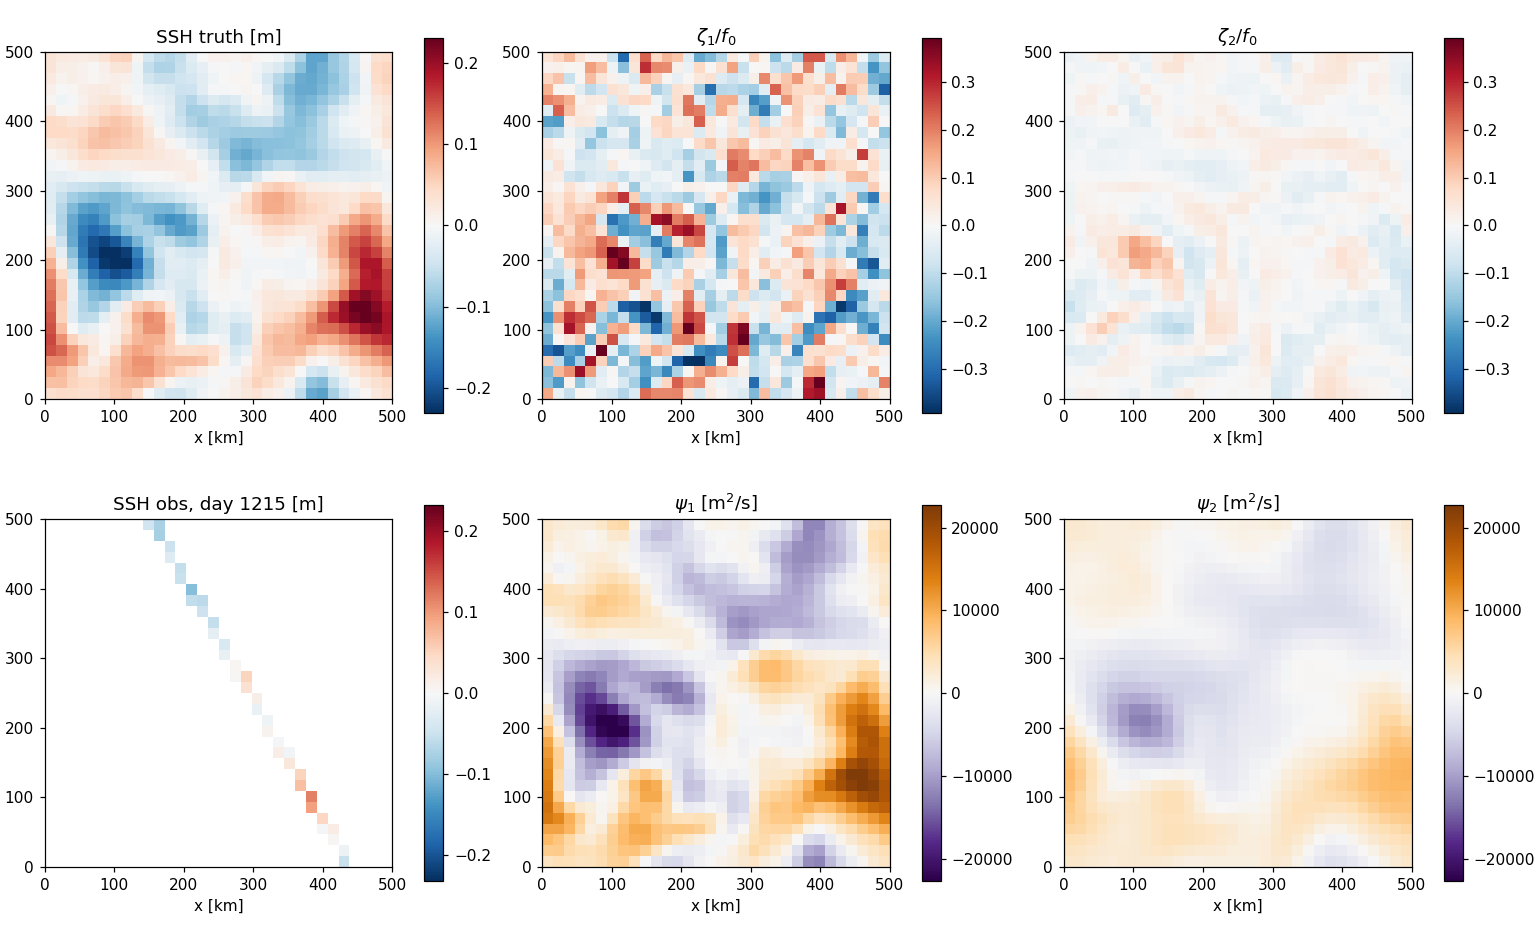

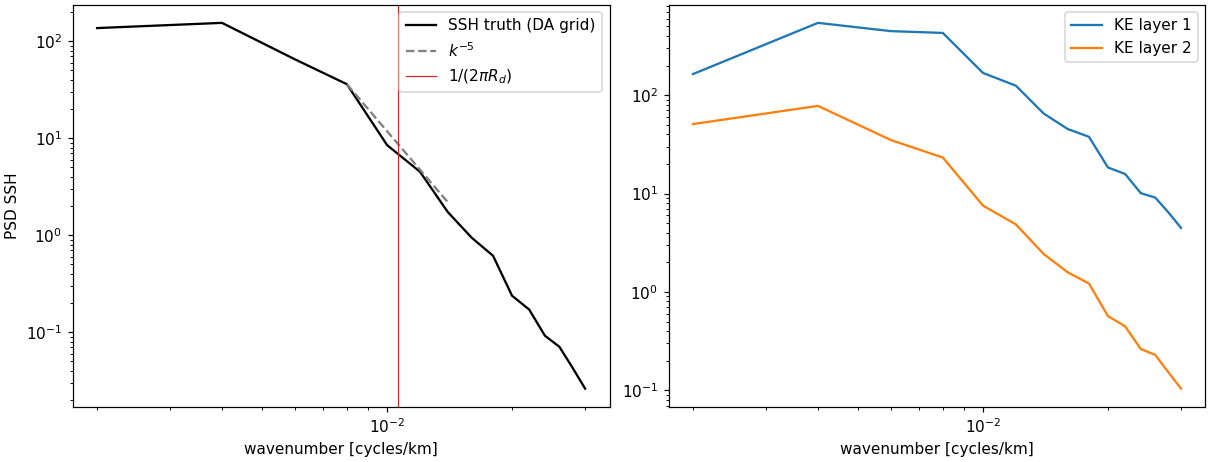

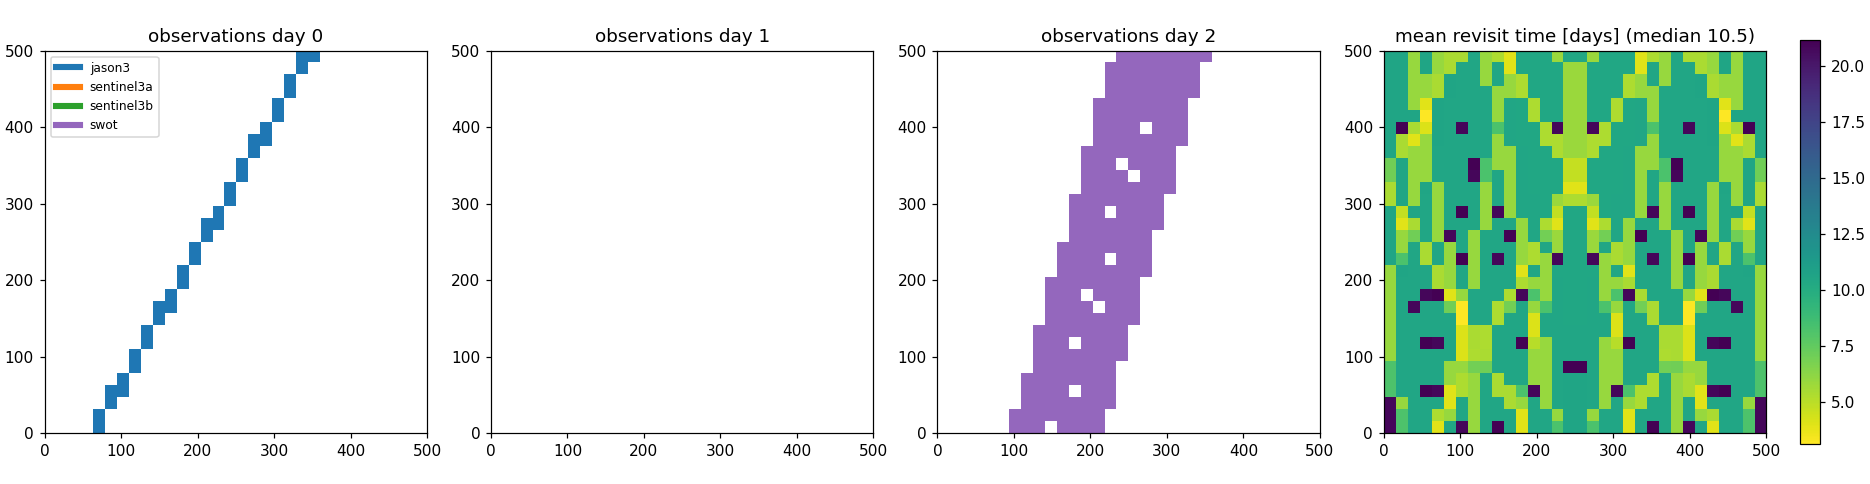

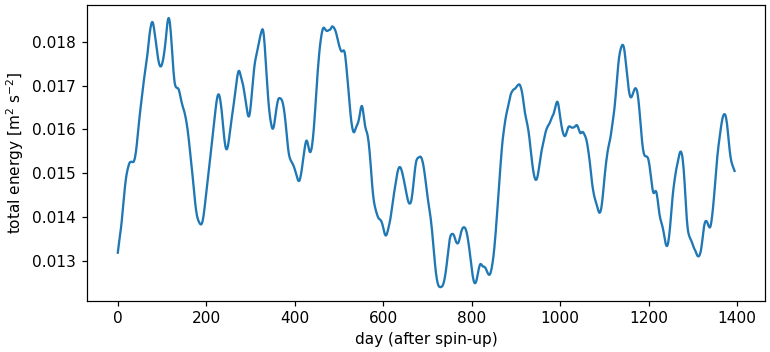

In [4]:
for f in ["snapshot_test_day0.png", "spectra.png", "obs_coverage.png", "energy.png"]:
    if (FIG / f).exists():
        display(Image(filename=str(FIG / f)))

In [5]:
anim = FIG / "truth_obs.mp4"
display(Video(str(anim), embed=True, width=900) if anim.exists() else Image(filename=str(anim.with_suffix(".gif"))))

## 2. 4DVarNet

Same components as `xp=qg2l_4dvarnet`: `src.models.GradSolver` with the bilinear AE prior and the ConvLSTM
gradient model (circular padding), trained with `LitQG2L` (subclass of `Lit4dVarNet`). The test step blends the
overlapping windows and writes `reconstructions/4dvarnet.nc`.

In [6]:
import copy
import pytorch_lightning as pl
import src.models
from contrib.qg2l.data import QG2LDataModule, qg_rec_weight, n_channels
from contrib.qg2l.models import LitQG2L, periodic

pl.seed_everything(333)
LAYERS = [1, 2]
C = n_channels(NET["n_time"], LAYERS)
dm = QG2LDataModule(str(DATA), n_time=NET["n_time"], layers=LAYERS, aug_factor=NET["aug_factor"],
                    dl_kw=dict(batch_size=NET["batch_size"], num_workers=0))

solver = src.models.GradSolver(
    prior_cost=periodic(src.models.BilinAEPriorCost(C, NET["hidden_prior"], downsamp=NET["downsamp"], bilin_quad=False)),
    obs_cost=src.models.BaseObsCost(),
    grad_mod=periodic(src.models.ConvLstmGradModel(C, NET["hidden_grad"], downsamp=NET["downsamp"])),
    n_step=NET["n_step"], lr_grad=1e3,
)

def opt_fn(lit, lr=1e-3):   # same as src.utils.cosanneal_lr_adam
    opt = torch.optim.Adam([
        {"params": lit.solver.grad_mod.parameters(), "lr": lr},
        {"params": lit.solver.obs_cost.parameters(), "lr": lr},
        {"params": lit.solver.prior_cost.parameters(), "lr": lr / 2},
    ])
    return {"optimizer": opt, "lr_scheduler": torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=NET["epochs"])}

lit = LitQG2L(solver=solver, rec_weight=qg_rec_weight(NET["n_time"], LAYERS, CFG["nx"]), opt_fn=opt_fn,
              persist_rw=False, export_path=str(REC / "4dvarnet.nc"))
# ---- checkpoints: resume / skip instead of restarting from scratch -----------------------
RETRAIN = False   # True -> ignore existing checkpoints and train from scratch
TAG = (f"nt{NET['n_time']}_h{NET['hidden_prior']}-{NET['hidden_grad']}_s{NET['n_step']}"
       f"_ds{NET['downsamp']}_L{''.join(map(str, LAYERS))}")      # one checkpoint folder per architecture
CKPT_DIR = OUT / "checkpoints" / TAG


def ckpt_epoch(path):
    return torch.load(path, map_location="cpu", weights_only=False)["epoch"]


def compatible(path):
    try:
        copy.deepcopy(lit).load_state_dict(torch.load(path, map_location="cpu", weights_only=False)["state_dict"],
                                           strict=True)
        return True
    except Exception:
        return False


resume = None
if not RETRAIN:
    if (CKPT_DIR / "last.ckpt").exists():
        resume = CKPT_DIR / "last.ckpt"
    else:
        # checkpoints of earlier notebook runs (Lightning default folders), if the architecture matches
        legacy = sorted((OUT / "logs" / "4dvarnet").glob("version_*/checkpoints/*.ckpt"), key=lambda q: q.stat().st_mtime)
        legacy = [q for q in legacy if compatible(q)]
        if legacy:
            resume = max(legacy, key=ckpt_epoch)

ckpt_cb = pl.callbacks.ModelCheckpoint(dirpath=str(CKPT_DIR), monitor="val_mse", save_top_k=1, save_last=True,
                                       filename="best-{epoch:03d}-{val_mse:.5f}")
logger = pl.loggers.CSVLogger(str(OUT / "logs"), name="4dvarnet")
trainer = pl.Trainer(max_epochs=NET["epochs"], accelerator="auto", devices=1, inference_mode=False,
                     gradient_clip_val=0.5, logger=logger, callbacks=[ckpt_cb])

done = resume is not None and ckpt_epoch(resume) + 1 >= NET["epochs"]
if done:
    best = sorted(CKPT_DIR.glob("best-*.ckpt")) or [resume]
    print(f"training already finished ({resume}) -> test only with {best[-1]}")
    trainer.test(lit, datamodule=dm, ckpt_path=str(best[-1]))
else:
    if resume is not None:
        print(f"resuming from {resume} (epoch {ckpt_epoch(resume)})")
    else:
        print(f"training from scratch, checkpoints in {CKPT_DIR}")
    trainer.fit(lit, datamodule=dm, ckpt_path=str(resume) if resume is not None else None)
    trainer.test(lit, datamodule=dm, ckpt_path="best")

Global seed set to 333
/Odyssey/private/m19beauc/conda_envs/4dvarnet-starter/lib/python3.11/site-packages/lightning_fabric/plugins/environments/slurm.py:168: PossibleUserWarning: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /Odyssey/private/m19beauc/conda_envs/4dvarnet-starte ...
  rank_zero_warn(
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA A100-SXM4-80GB') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
Restoring states from the checkpoint path at data/qg2

training already finished (data/qg2l_nb_small/checkpoints/nt21_h64-96_s15_dsNone_L12/last.ckpt) -> test only with data/qg2l_nb_small/checkpoints/nt21_h64-96_s15_dsNone_L12/best-epoch=119-val_mse=0.16287.ckpt
Norm stats (1.4618361859550233e-12, 0.0552196279168129)


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Loaded model weights from the checkpoint at data/qg2l_nb_small/checkpoints/nt21_h64-96_s15_dsNone_L12/best-epoch=119-val_mse=0.16287.ckpt
/Odyssey/private/m19beauc/conda_envs/4dvarnet-starter/lib/python3.11/site-packages/pytorch_lightning/utilities/_pytree.py:21: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return [pytree], LeafSpec()
/Odyssey/private/m19beauc/conda_envs/4dvarnet-starter/lib/python3.11/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:438: PossibleUserWarning: The dataloader, test_dataloader, does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` (try 96 which is the number of cpus on this machine) in the `DataLoader` init to improve performance.
  rank_zero_warn(


Testing: 0it [00:00, ?it/s]


| rmse_ssh         |     0.0098 |
| mu_ssh           |     0.8554 |
| lx_ssh_km        |    53.1048 |
| rmse_layer2      |     0.0067 |
| mu_layer2        |     0.7754 |
| lx_layer2_km     |    87.9336 |
wrote data/qg2l_nb_small/logs/4dvarnet/version_6/test_data.nc
wrote data/qg2l_nb_small/reconstructions/4dvarnet.nc


In [7]:
# training curves of all runs of this notebook (resumed runs are concatenated, last value per epoch kept)
runs = sorted((OUT / "logs" / "4dvarnet").glob("version_*/metrics.csv"), key=lambda q: q.stat().st_mtime)
hist = (pd.concat([pd.read_csv(r) for r in runs]).groupby("epoch").last()
        if runs else pd.DataFrame())
if not hist.empty:
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), constrained_layout=True)
    hist[[c for c in ["train_loss", "val_loss"] if c in hist]].dropna(how="all").plot(ax=ax[0], logy=True)
    hist[[c for c in ["train_mse", "val_mse"] if c in hist]].dropna(how="all").plot(ax=ax[1], logy=True)
    ax[0].set_title("loss"); ax[1].set_title("MSE (x 1e4, physical units)")

## 3. Cycled 4DVar (strong and weak constraint)

Low-resolution QG model (= model error with respect to the high-resolution truth), spectral B from the training
climatology, L-BFGS, adjoint by autograd. `b_scale` / `q_scale` / `window_days` should be tuned on the validation
split (`split="val"`) before the final comparison.

In [8]:
from contrib.qg2l.fourdvar import run_4dvar

t0, t1 = CFG["splits"]["test"]


def up_to_date(path, mode):
    """Existing 4DVar output covers the current test period with the current settings?"""
    if not path.exists():
        return False
    r = xr.open_dataset(path, decode_times=False)
    cfg = json.loads(r.attrs.get("config", "{}"))
    same_time = r.sizes["time"] == t1 - t0 and np.allclose(r.time.values, ds.time.values[t0:t1])
    want = dict(mode=mode, window_days=VAR["window_days"], b_scale=VAR["b_scale"], q_scale=VAR["q_scale"],
                n_iter=VAR["n_iter"], spinup_days=VAR["spinup_days"])
    same_cfg = all(cfg.get(k) == v for k, v in want.items())
    r.close()
    return same_time and same_cfg


for mode in ["strong", "weak"]:
    out = REC / f"4dvar_{mode}_test.nc"
    if up_to_date(out, mode):
        print(f"{out} up to date -> skipped")
        continue
    if out.exists():
        print(f"{out} computed for another period / settings -> recomputing")
        out.unlink()
    run_4dvar(str(DATA), str(out), mode=mode, window_days=VAR["window_days"], b_scale=VAR["b_scale"],
              q_scale=VAR["q_scale"], n_iter=VAR["n_iter"], spinup_days=VAR["spinup_days"], device=DEVICE)

data/qg2l_nb_small/reconstructions/4dvar_strong_test.nc up to date -> skipped
data/qg2l_nb_small/reconstructions/4dvar_weak_test.nc up to date -> skipped


## 4. Comparison

In [9]:
RECS = {"4dvarnet": REC / "4dvarnet.nc", "4dvar_strong": REC / "4dvar_strong_test.nc",
        "4dvar_weak": REC / "4dvar_weak_test.nc"}
RECS = {k: v for k, v in RECS.items() if v.exists()}
t0, t1 = CFG["splits"]["test"]
f0g = KW["f0"] / KW["g"]
truth = ds.psi.values[t0:t1].astype(np.float64)
rec = {k: xr.open_dataset(v, decode_times=False).psi.values.astype(np.float64) for k, v in RECS.items()}

pd.DataFrame({k: json.loads(xr.open_dataset(v, decode_times=False).attrs["scores"]) for k, v in RECS.items()}).round(4)

,4dvarnet,4dvar_strong,4dvar_weak
rmse_ssh,0.0098,0.0090,0.0090
mu_ssh,0.8554,0.8662,0.8669
lx_ssh_km,53.1048,60.4072,60.1652
rmse_layer2,0.0067,0.0047,0.0043
mu_layer2,0.7754,0.8443,0.8582
lx_layer2_km,87.9336,59.3891,58.5273


In [10]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True, constrained_layout=True)
days = ds.time.values[t0:t1]
for name, r in rec.items():
    for l in range(2):
        ax[l].plot(days, f0g * np.sqrt(((r[:, l] - truth[:, l]) ** 2).mean((-1, -2))), label=name)
ax[0].set_title("RMSE layer 1 (SSH) [m]"); ax[1].set_title("RMSE layer 2 (SSH-equivalent) [m]")
ax[1].set_xlabel("day"); ax[0].legend();

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
dx = KW["L"] / KW["nx"]
for name, r in rec.items():
    for l in range(2):
        wl, score, lam = metrics.psd_score(f0g * r[:, l], f0g * truth[:, l], dx)
        ax[l].semilogx(wl, score, label=f"{name} ({lam:.0f} km)")
for l in range(2):
    ax[l].axhline(0.5, c="gray", lw=0.8); ax[l].set_ylim(-0.2, 1.05); ax[l].invert_xaxis()
    ax[l].set_xlabel("wavelength [km]"); ax[l].set_title(f"PSD score, layer {l+1}"); ax[l].legend()

In [12]:
day = (t1 - t0) // 2
names = list(rec)
ext = [0, KW["L"] / 1e3, 0, KW["L"] / 1e3]
fig, ax = plt.subplots(2, 2 + 2 * len(names), figsize=(3.2 * (2 + 2 * len(names)), 6.2), constrained_layout=True)
obs = ds.obs_ssh.values[t0 + day]
for l in range(2):
    v = np.abs(f0g * truth[day, l]).max()
    panels = [(f"truth L{l+1}", f0g * truth[day, l], v), ("obs (SSH)" if l == 0 else "", obs if l == 0 else None, v)]
    e_max = max(np.abs(f0g * (rec[n][day, l] - truth[day, l])).max() for n in names)
    for n in names:
        panels.append((f"{n} L{l+1}", f0g * rec[n][day, l], v))
    for n in names:
        panels.append((f"err {n} L{l+1}", f0g * (rec[n][day, l] - truth[day, l]), e_max))
    for a, (title, fld, vm) in zip(ax[l], panels):
        a.set_xticks([]); a.set_yticks([])
        if fld is None:
            a.axis("off"); continue
        a.imshow(fld, origin="lower", extent=ext, cmap="RdBu_r", vmin=-vm, vmax=vm); a.set_title(title, fontsize=9)
fig.suptitle(f"test day {day}");

## 5. Lyapunov diagnostic

BLV / CLV of the low-resolution DA model along the true trajectory (energy norm), and projection of each error on the
unstable / neutral / stable-resolved / residual subspaces. Check `n_unstable < k` in the summary.

In [13]:
from contrib.qg2l.diag import run_diag

summary_lyap = run_diag(str(DATA), {k: str(v) for k, v in RECS.items()}, str(OUT / "diag"), k=LYAP["k"],
                        n_transient_fwd=LYAP["n_fwd"], n_transient_bwd=LYAP["n_bwd"], device=DEVICE)

[lyap] 1/179 lambda_1=-0.882/day  n_pos=0/192
[lyap] 21/179 lambda_1=0.042/day  n_pos=24/192
[lyap] 41/179 lambda_1=0.076/day  n_pos=87/192
[lyap] 61/179 lambda_1=0.097/day  n_pos=91/192
[lyap] 81/179 lambda_1=0.100/day  n_pos=88/192
[lyap] 101/179 lambda_1=0.109/day  n_pos=89/192
[lyap] 121/179 lambda_1=0.105/day  n_pos=88/192
[lyap] 141/179 lambda_1=0.106/day  n_pos=88/192
[lyap] 161/179 lambda_1=0.103/day  n_pos=89/192
[lyap] 179/179 lambda_1=0.101/day  n_pos=90/192
{
 "k": 192,
 "n_unstable": 73,
 "n_neutral": 37,
 "lambda1_per_day": 0.10111040826180125,
 "kaplan_yorke_dim": NaN,
 "warning": null,
 "methods": {
  "4dvarnet": {
   "mean_error_energy": 0.0021592481534092327,
   "mean_blv_unstable": 0.08784522872913623,
   "mean_blv_neutral": 0.06986528854038543,
   "mean_blv_stable_resolved": 0.1495605942109367,
   "mean_residual": 0.6927288885195415,
   "mean_blv_unstable_abs": 0.00018310571324598376,
   "mean_blv_neutral_abs": 0.00017830427233366908,
   "mean_blv_stable_resolved_ab

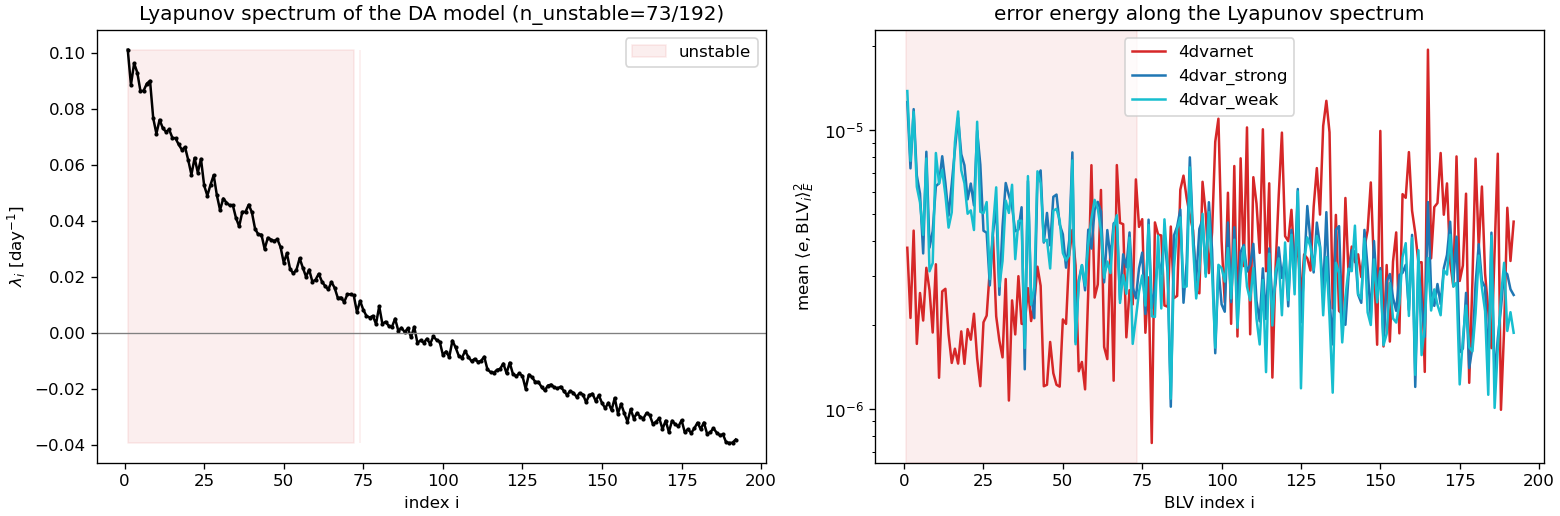

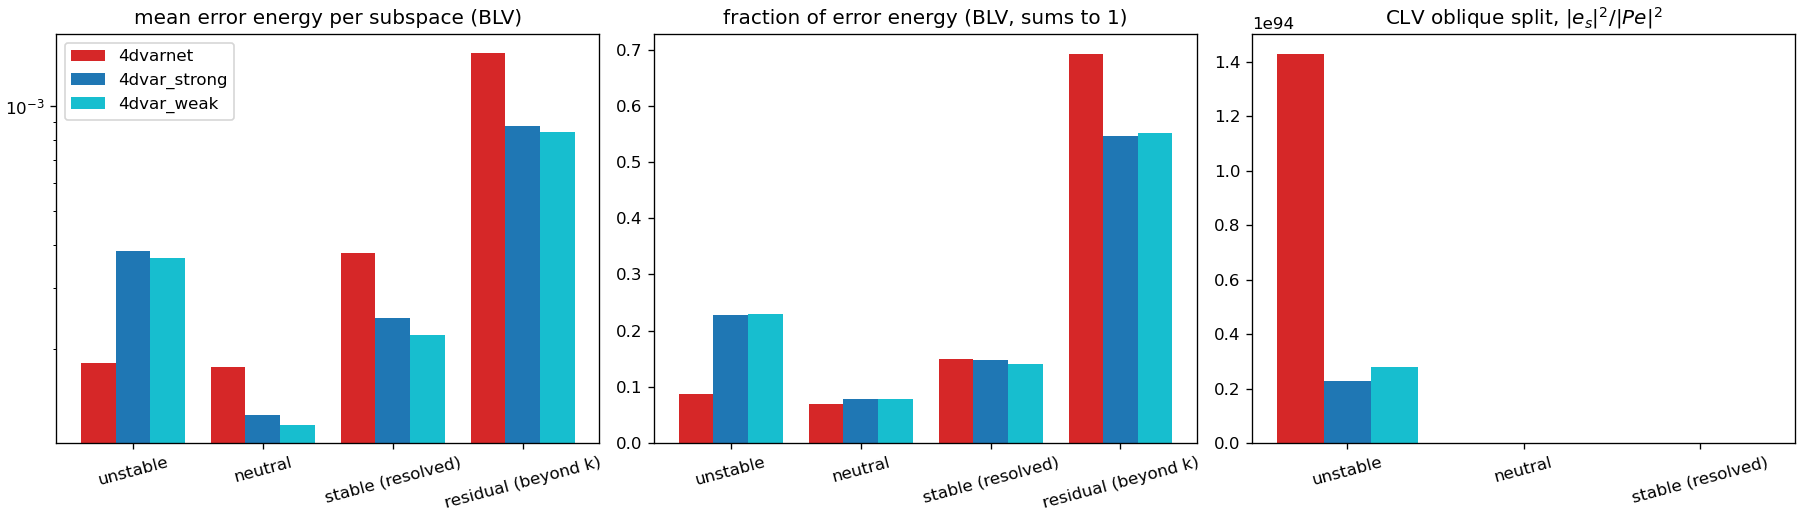

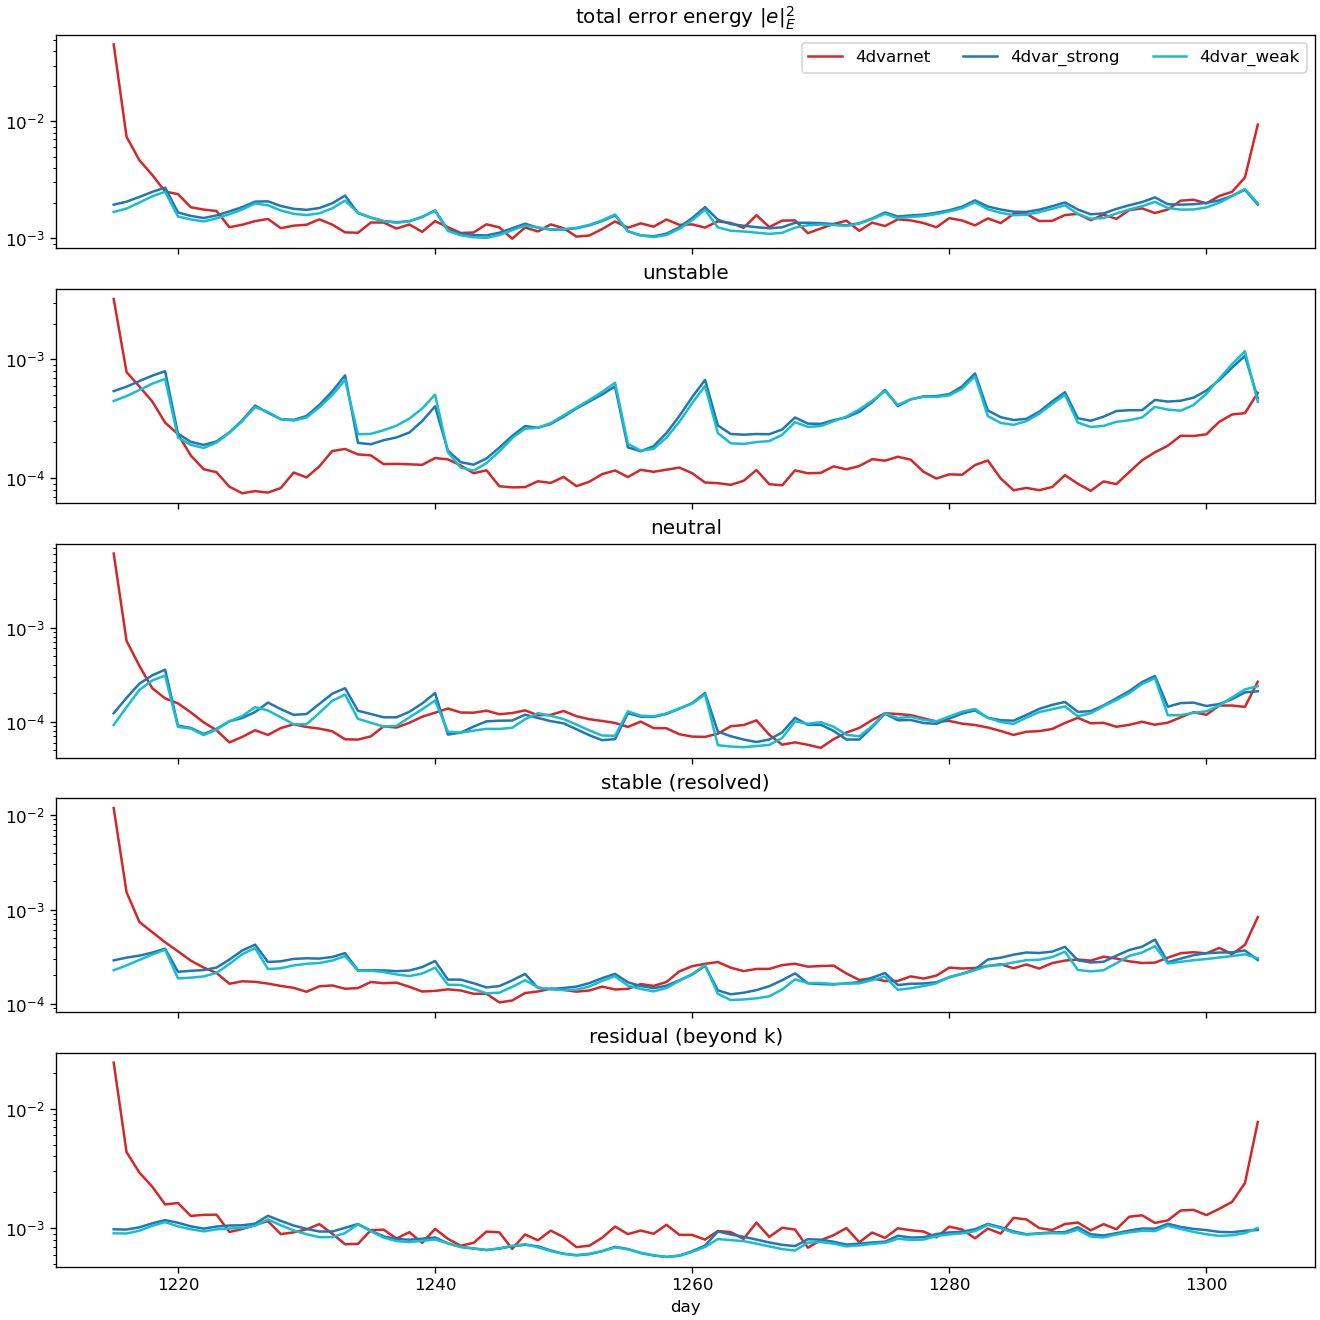

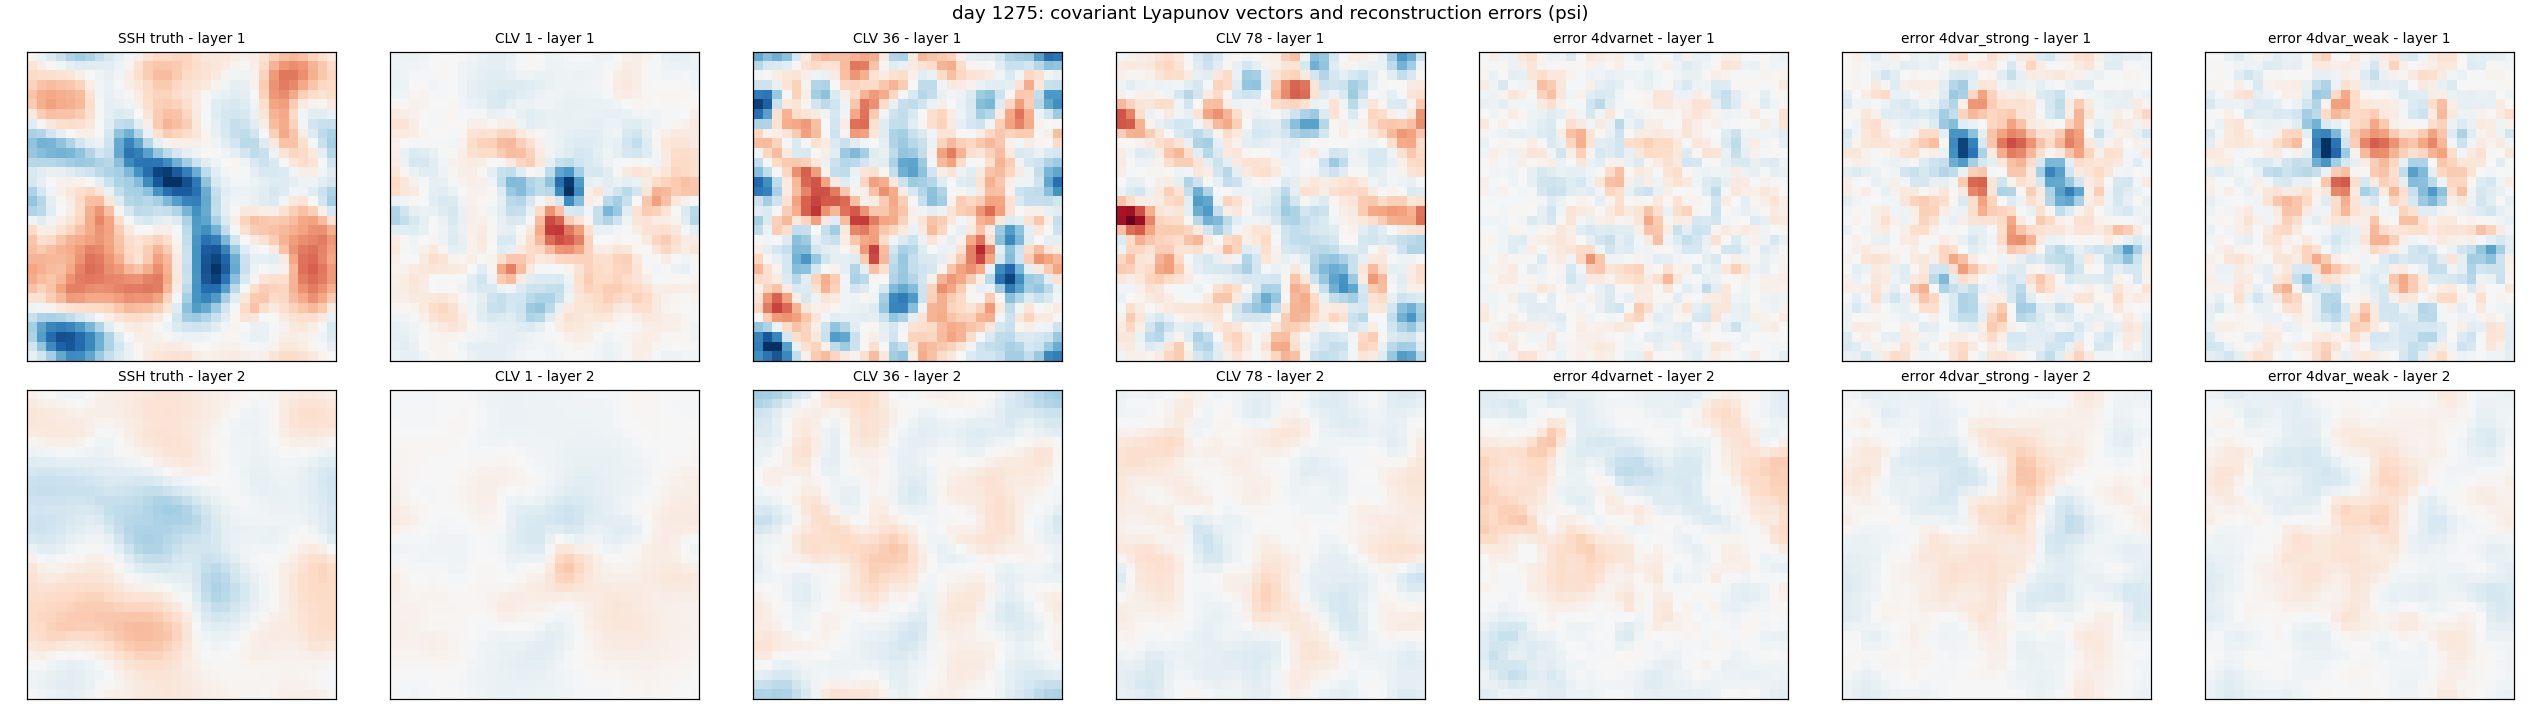

In [14]:
for f in ["lyapunov_spectrum_error_distribution.png", "subspace_summary.png",
          "error_energy_by_subspace.png", "clv_and_error_maps.png"]:
    display(Image(filename=str(OUT / "diag" / f)))
anim = OUT / "diag" / "reconstructions.mp4"
display(Video(str(anim), embed=True, width=1100) if anim.exists() else Image(filename=str(anim.with_suffix(".gif"))))

In [15]:
s = summary_lyap
print(f"lambda_1 = {s['lambda1_per_day']:.3f} /day, n_unstable = {s['n_unstable']} / k = {s['k']}", s["warning"] or "")
pd.DataFrame(s["methods"]).T.round(4)

lambda_1 = 0.101 /day, n_unstable = 73 / k = 192 


,mean_error_energy,mean_blv_unstable,mean_blv_neutral,mean_blv_stable_resolved,mean_residual,mean_blv_unstable_abs,mean_blv_neutral_abs,mean_blv_stable_resolved_abs,mean_residual_abs,mean_clv_unstable,mean_clv_neutral,mean_clv_stable_resolved
4dvarnet,0.0022,0.0878,0.0699,0.1496,0.6927,0.0002,0.0002,0.0004,0.0014,1.429682e+94,4.415931e+86,5.712355e+58
4dvar_strong,0.0016,0.2278,0.0783,0.1483,0.5456,0.0004,0.0001,0.0002,0.0009,2.296168e+93,3.986468e+86,5.933565e+58
4dvar_weak,0.0015,0.2300,0.0776,0.1404,0.5521,0.0004,0.0001,0.0002,0.0008,2.791890e+93,2.302330e+86,3.439140e+58


In [16]:
# relative gain of 4DVarNet per subspace (1 - E_4dvarnet / E_4dvar)
pd.DataFrame(s.get(f"gain_vs_{list(s['methods'])[0]}", {})).T.round(3)

,blv_unstable,blv_neutral,blv_stable_resolved,residual
4dvar_strong,0.521,-0.372,-0.540,-0.623
4dvar_weak,0.501,-0.464,-0.714,-0.693
